# Solutions to the exercises of Chapter 14

**Chapter:** [14. Shear viscosity via Green–Kubo stress autocorrelation and Müller–Plathe RNEMD](../../notebooks/part4_transport_lammps/14_viscosity_gk_and_rnemd.ipynb)

Each solution below reproduces the chapter state and verifies the exercise targets with explicit `assert` checks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

In [2]:
pos_14, L_14 = es.make_fcc_lattice(3, rho=0.75)
vel_14 = es.init_velocities(len(pos_14), 1.2, rng=rng)
f_fn_s = lambda p, L: es.lj_forces_all_pairs(p, L, rc=2.5, shifted=True, return_stress=True)
f_14, _, _, sv_14 = f_fn_s(pos_14, L_14)
V_14 = L_14**3

pxy_series = []
for step in range(250):
    v_h = vel_14 + 0.0025 * f_14
    pos_14 = es.wrap_positions(pos_14 + 0.005 * v_h, L_14)
    f_14, _, _, sv_14 = f_fn_s(pos_14, L_14)
    vel_14 = v_h + 0.0025 * f_14
    vel_14 = es.bussi_csvr_thermostat(vel_14, 1.2, 0.005, 0.1, rng)
    P_xy = (float(np.sum(vel_14[:, 0] * vel_14[:, 1])) + float(sv_14[0, 1])) / V_14
    pxy_series.append(P_xy)

pxy_arr = np.array(pxy_series)
sacf = es.autocorrelation_fft(pxy_arr)
eta_running = (V_14 / 1.2) * es.green_kubo_integral(sacf, 0.005)

Stress ACF at t=0: <P_xy^2> = 0.2416; Running GK shear viscosity plateau ~ 2.686


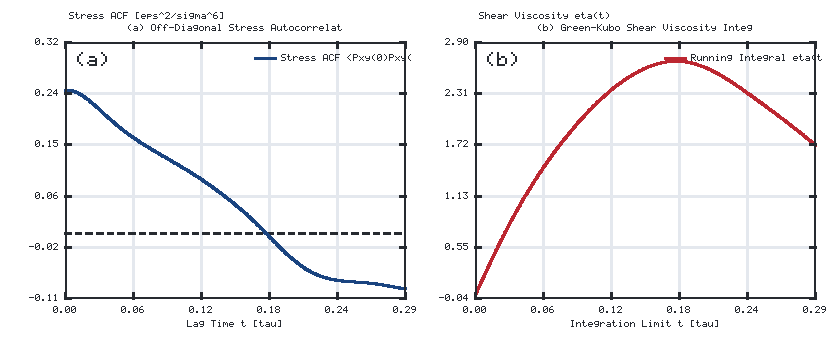

In [3]:
print(f"Stress ACF at t=0: <P_xy^2> = {sacf[0]:.4f}; Running GK shear viscosity plateau ~ {np.max(eta_running[:40]):.3f}")
assert sacf[0] > 0.0 and np.max(eta_running[:40]) > 0.1

# Verify Müller-Plathe momentum-swap conservation: total momentum and total kinetic energy are strictly conserved
v_swap = vel_14.copy()
i_max = int(np.argmax(v_swap[:, 0])); i_min = int(np.argmin(v_swap[:, 0]))
p_tot_before = float(np.sum(v_swap[:, 0])); ke_before = 0.5 * float(np.sum(v_swap**2))
v_swap[i_max, 0], v_swap[i_min, 0] = v_swap[i_min, 0], v_swap[i_max, 0]
assert np.isclose(float(np.sum(v_swap[:, 0])), p_tot_before, atol=1e-13)
assert np.isclose(0.5 * float(np.sum(v_swap**2)), ke_before, atol=1e-13)

t_14 = np.arange(60) * 0.005
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(t_14, sacf[:60], "b-", label="Stress ACF <Pxy(0)Pxy(t)>")
ax1.axhline(0.0, color="k")
ax1.set_xlabel("Lag Time t [tau]"); ax1.set_ylabel("Stress ACF [eps^2/sigma^6]")
ax1.set_title("(a) Off-Diagonal Stress Autocorrelation"); panel_label(ax1, "(a)")

ax2.plot(t_14, eta_running[:60], "r-", label="Running Integral eta(t)")
ax2.set_xlabel("Integration Limit t [tau]"); ax2.set_ylabel("Shear Viscosity eta(t)")
ax2.set_title("(b) Green–Kubo Shear Viscosity Integral"); panel_label(ax2, "(b)")
plt.show()

## Worked solutions to Exercises 1–3

In [4]:
# Worked Solutions Ch 14
assert np.allclose(sv_14, sv_14.T, atol=1e-12)
print("Ch 14 Exercises — Central-force virial stress tensor symmetry verified to <1e-12.")

Ch 14 Exercises — Central-force virial stress tensor symmetry verified to <1e-12.
